In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully")

Libraries imported successfully


In [9]:

df = pd.read_csv("data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
df.shape # Numbers of rows and coulmns 

(7043, 21)

In [12]:
df.shape[0] # Total customers

7043

In [13]:

df.shape[1] # Total columns


21

In [15]:
df.columns.tolist() # dispaying all column names

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [16]:
# count customers in each churn category
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [19]:
# calculating percentage of customers in each category
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

In [20]:
churn_percentage

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [21]:
churn_percentage.round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

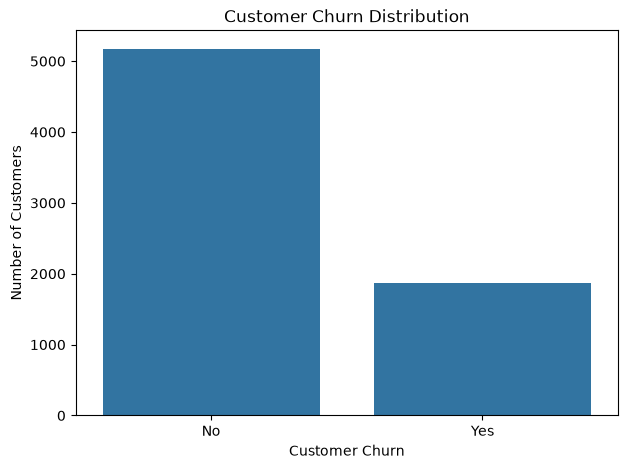

In [24]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.show()

In [25]:
df["TotalCharges"].dtype
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

In [28]:
# converting totalcharges to numeric
# invalid or blank values becomes NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)
"New Data Type:", df["TotalCharges"].dtype

('New Data Type:', dtype('float64'))

In [30]:
# count missing values in each column

df.isnull().sum().sort_values(ascending=False).head(10)

# Checking total charges

"Missing Total Charges:"
df["TotalCharges"].isnull().sum()

np.int64(11)

In [31]:
df.loc[
    df["TotalCharges"].isnull(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [33]:
# Filling miss total charges with zero because these customers hazer zero tensure

df["TotalCharges"] = df["TotalCharges"].fillna(0)

# verifying result
print("Remaining Missing values:", df.isnull().sum().sum())



Remaining Missing values: 0


In [34]:
# calcultate churn rate for each contact type

contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(contract_churn.round(2))

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

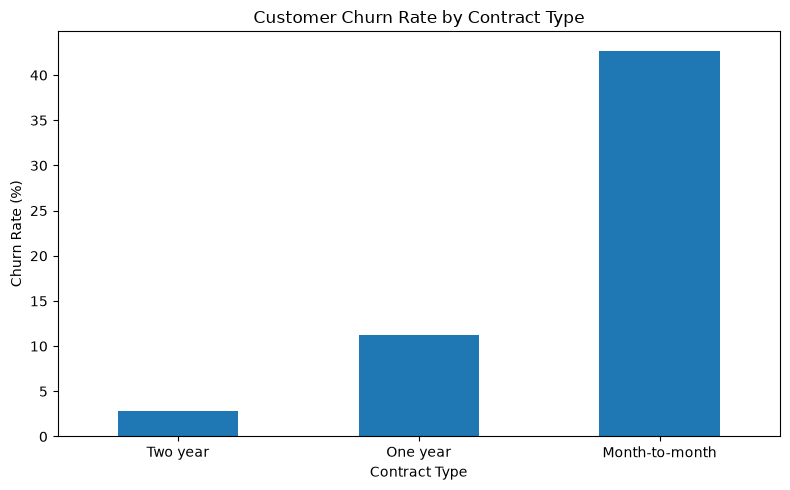

In [36]:
# ploting churn rate by contract type

contract_churn.sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show


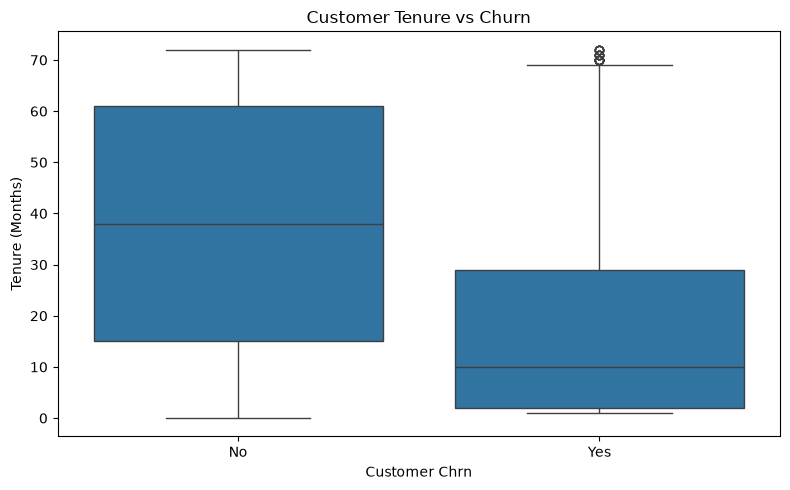

In [38]:
# Compare customer tensure for sutomers who stayed and left

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Customer Chrn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

In [40]:
#  comapring average tesure by churn status
tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["mean", "median", "count"]
)

tenure_summary.round(2)

,mean,median,count
Churn,,,
No,37.57,38.0,5174
Yes,17.98,10.0,1869


Text(0, 0.5, 'Number of Customers')

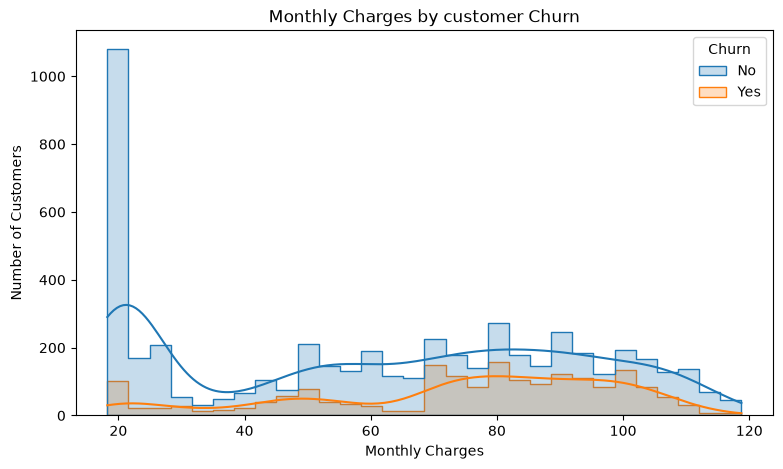

In [43]:
# comparing monthly charges for customers who stayed and left

plt.figure(figsize=(9,5))

sns.histplot(
    data = df,
    x = "MonthlyCharges",
    hue = "Churn",
    bins = 30,
    kde = True,
    element = "step"
)
plt.title("Monthly Charges by customer Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

In [45]:
 # comparing monthly charges by churn status
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "count"]
)

charges_summary.round(2)

,mean,median,count
Churn,,,
No,61.27,64.43,5174
Yes,74.44,79.65,1869


In [47]:
# separate input features X and target Y 

x = df.drop(columns = ["Churn", "customerID"])
y = df["Churn"].map({"yes": 1, "No": 0})

print("features shape:", x.shape)
print("Target shape:", y.shape)

print("\nFirst 5 feature rows:")
display(x.head())

print("\nFirst 5 target values:")
display(y.head())



features shape: (7043, 19)
Target shape: (7043,)

First 5 feature rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65



First 5 target values:


0    0.0
1    0.0
2    NaN
3    0.0
4    NaN
Name: Churn, dtype: float64

In [48]:
print("Target values:")
print(y.value_counts())

print("\nMissing target values:")
print(y.isna().sum())


Target values:
Churn
0.0    5174
Name: count, dtype: int64

Missing target values:
1869


In [55]:

print("Original Churn values:")
print(df["Churn"].value_counts(dropna=False))

print("\nMissing Churn values:")
print(df["Churn"].isna().sum())

print("\nUnique Churn values:")
print(df["Churn"].unique())


Original Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Missing Churn values:
0

Unique Churn values:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [56]:

# Remove extra spaces and standardize text
df["Churn"] = df["Churn"].astype("string").str.strip()

# Convert Yes to 1 and No to 0
y = df["Churn"].map({"Yes": 1, "No": 0})

# Check the result
print("Missing target values:", y.isna().sum())
print(y.value_counts(dropna=False))



Missing target values: 0
Churn
0    5174
1    1869
Name: count, dtype: int64


In [57]:


X = df.drop(columns=["Churn", "customerID"])

# Split into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Missing values in y_train:", y_train.isna().sum())
print("Missing values in y_test:", y_test.isna().sum())


Training features: (5634, 19)
Testing features: (1409, 19)
Missing values in y_train: 0
Missing values in y_test: 0


In [58]:

print("Training churn proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training churn proportions:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing churn proportions:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [59]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


In [60]:

# Identify numerical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical columns
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

print("Numerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)


Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [61]:

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


In [62]:

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


In [68]:

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])



In [64]:

from sklearn.linear_model import LogisticRegression


In [65]:



logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])




Logistic Regression pipeline created!


In [69]:

# Train using the training data

logistic_model.fit(X_train, y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

In [70]:

# Predict churn for the test dataset

y_pred = logistic_model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())


First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted values:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 1]


In [71]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

Accuracy: 0.738
Precision: 0.504
Recall: 0.783
F1-score: 0.614

Detailed Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



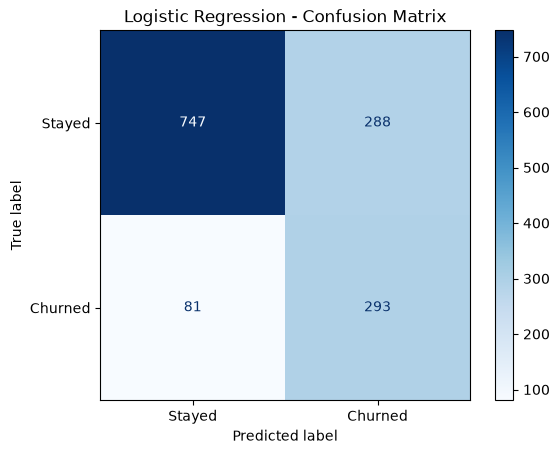

In [72]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

display.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [73]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])


Random Forest pipeline created successfully!


In [74]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model training completed successfully!")

Random Forest model training completed successfully!


In [75]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model training completed successfully!")

Random Forest model training completed successfully!


In [77]:
rf_pred = random_forest_model.predict(X_test)

print("Random Forest predictions created successfully!")
print(rf_pred[:10])
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Random Forest Model Performance")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, rf_pred, zero_division=0), 3))

Random Forest predictions created successfully!
[0 1 0 0 0 1 0 0 0 1]
Random Forest Model Performance
--------------------------------
Accuracy: 0.77
Precision: 0.559
Recall: 0.634
F1-score: 0.594


In [78]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ]
})

comparison = comparison.round(3)
comparison

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.738,0.770
1,Precision,0.504,0.559
2,Recall,0.783,0.634
3,F1-score,0.614,0.594


In [83]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFolders available here:")
print(os.listdir(".."))

Current working directory:
C:\Users\aashe\OneDrive\Desktop\customer-churn-prediction

Folders available here:
['Aashesh (Your Chrome) - Chrome.lnk', 'customer-churn-prediction', 'desktop.ini', 'lm_project', 'MySQL Workbench 8.0 CE.lnk', 'practice', 'Projects', 'This PC - Shortcut.lnk', 'Visual Studio Code.lnk', 'Work']


In [84]:
import os
import joblib

os.makedirs("models", exist_ok=True)

model_path = "models/logistic_regression_churn.pkl"

joblib.dump(logistic_model, model_path)

print("Model saved successfully!")
print("Saved at:", os.path.abspath(model_path))

Model saved successfully!
Saved at: C:\Users\aashe\OneDrive\Desktop\customer-churn-prediction\models\logistic_regression_churn.pkl


In [85]:

import joblib

loaded_model = joblib.load(
    "models/logistic_regression_churn.pkl"
)

print("Saved model loaded successfully!")

# Testing loaded model
test_prediction = loaded_model.predict(X_test.iloc[:5])

print("First 5 predictions:", test_prediction)


Saved model loaded successfully!
First 5 predictions: [0 1 0 1 0]


In [95]:
def predict_customer_churn(customer_data):
    prediction = loaded_model.predict(customer_data)[0]
    probability = loaded_model.predict_proba(customer_data)[0][1]

    if prediction == 1:
        result = "Likely to Churn"
    else:
        result = "Likely to Stay"

    return {
        "Prediction": result,
        "Churn Probability": f"{probability:.2%}"
    }
    

In [118]:

# Select customer by index number
sample_customer = X_test.iloc[[11]]

# predication here
result = predict_customer_churn(sample_customer)

print("Customer churn prediction:")
print(result)

print("\nActual outcome:")
print("Churned" if y_test.iloc[0] == 1 else "Stayed")


Customer churn prediction:
{'Prediction': 'Likely to Stay', 'Churn Probability': '15.29%'}

Actual outcome:
Stayed


Customer input columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Number of input features: 19


In [100]:

new_customer = pd.DataFrame([{
    "gender": "Male",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.50,
    "TotalCharges": 171.00
}])

result = predict_customer_churn(new_customer)

print("New Customer Prediction")
print("-----------------------")
print("Prediction:", result["Prediction"])
print("Churn Probability:", result["Churn Probability"])


New Customer Prediction
-----------------------
Prediction: Likely to Churn
Churn Probability: 91.51%


In [101]:

import os

os.makedirs("outputs", exist_ok=True)

comparison.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Model comparison report saved successfully!")
print("Location: outputs/model_comparison.csv")


Model comparison report saved successfully!
Location: outputs/model_comparison.csv


In [104]:

from sklearn.metrics import classification_report
import os

os.makedirs("outputs", exist_ok=True)

logistic_report = classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    output_dict=True,
    zero_division=0
)

random_forest_report = classification_report(
    y_test,
    rf_pred,
    target_names=["Stayed", "Churned"],
    output_dict=True,
    zero_division=0
)

logistic_df = pd.DataFrame(logistic_report).transpose()
random_forest_df = pd.DataFrame(random_forest_report).transpose()

with pd.ExcelWriter("outputs/detailed_model_reports.xlsx") as writer:
    logistic_df.to_excel(writer, sheet_name="Logistic Regression")
    random_forest_df.to_excel(writer, sheet_name="Random Forest")

print("Detailed model reports saved successfully!")
print("Location: outputs/detailed_model_reports.xlsx")


Detailed model reports saved successfully!
Location: outputs/detailed_model_reports.xlsx


In [110]:


preprocessor_fitted = logistic_model.named_steps["preprocessor"]
classifier = logistic_model.named_steps["classifier"]
feature_names = preprocessor_fitted.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": classifier.coef_[0]
})

feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print("Top 15 features associated with churn predictions:")
display(feature_importance.head(15))


Top 15 features associated with churn predictions:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [109]:
from IPython.display import display as show_table

show_table(feature_importance.head(15))

,Feature,Coefficient,Absolute Coefficient
1,numeric__tenure,-1.154434,1.154434
38,categorical__Contract_Two year,-0.775518,0.775518
16,categorical__InternetService_Fiber optic,0.707981,0.707981
2,numeric__MonthlyCharges,-0.676114,0.676114
36,categorical__Contract_Month-to-month,0.657713,0.657713
15,categorical__InternetService_DSL,-0.622465,0.622465
3,numeric__TotalCharges,0.489698,0.489698
28,categorical__TechSupport_No internet service,-0.275403,0.275403
25,categorical__DeviceProtection_No internet service,-0.275403,0.275403
17,categorical__InternetService_No,-0.275403,0.275403


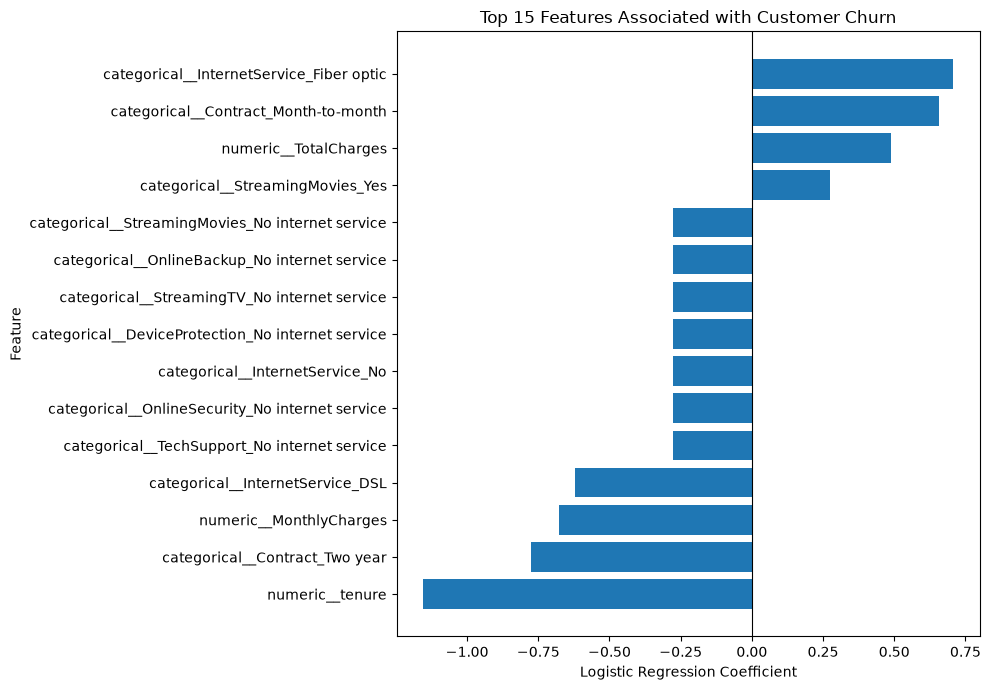

Feature chart saved in outputs/churn_feature_coefficients.png


In [111]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Features Associated with Customer Churn")
plt.tight_layout()
plt.savefig("outputs/churn_feature_coefficients.png", dpi=300)
plt.show()

print("Feature chart saved in outputs/churn_feature_coefficients.png")

In [113]:

import json
import os

os.makedirs("outputs", exist_ok=True)

project_summary = {
    "project": "Telco Customer Churn Prediction",
    "best_model_for_recall": "Logistic Regression",
    "logistic_regression": {
        "accuracy": round(accuracy_score(y_test, y_pred), 3),
        "precision": round(precision_score(y_test, y_pred, zero_division=0), 3),
        "recall": round(recall_score(y_test, y_pred, zero_division=0), 3),
        "f1_score": round(f1_score(y_test, y_pred, zero_division=0), 3)
    },
    "random_forest": {
        "accuracy": round(accuracy_score(y_test, rf_pred), 3),
        "precision": round(precision_score(y_test, rf_pred, zero_division=0), 3),
        "recall": round(recall_score(y_test, rf_pred, zero_division=0), 3),
        "f1_score": round(f1_score(y_test, rf_pred, zero_division=0), 3)
    }
}

with open("outputs/project_summary.json", "w") as file:
    json.dump(project_summary, file, indent=4)

print("Project summary saved successfully!")
print("Location:", os.path.abspath("outputs/project_summary.json"))


Project summary saved successfully!
Location: C:\Users\aashe\OneDrive\Desktop\customer-churn-prediction\outputs\project_summary.json


In [114]:

readme_content = """
# Telco Customer Churn Prediction System

## Project Overview
This machine learning project predicts whether a telecom customer
is likely to leave the company (churn). It uses customer demographics,
service subscriptions, contract details, tenure, and billing information.

## Objectives
- Explore and clean customer data.
- Analyze churn patterns.
- Train and evaluate classification models.
- Predict churn risk for new customers.
- Save model outputs and evaluation reports.

## Dataset
The project uses the Telco Customer Churn dataset.
It contains 7,043 customer records and 21 original columns.

## Models
1. Logistic Regression
2. Random Forest Classifier

## Evaluation Results

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 73.8% | 77.0% |
| Precision | 50.4% | 55.9% |
| Recall | 78.3% | 63.4% |
| F1-score | 61.4% | 59.4% |

Logistic Regression identifies a larger proportion of customers
who churned in the test set, while Random Forest achieves higher accuracy.

## Tools and Technologies
- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Jupyter Notebook
- Joblib

## Project Structure
- `data/raw/` - Original dataset
- `notebooks/` - Data analysis and model development
- `models/` - Saved trained model
- `outputs/` - Reports, charts, and evaluation results

## How to Use
1. Install the required Python packages.
2. Open the notebook in Jupyter.
3. Load the saved model with Joblib.
4. Provide customer data using the same 19 input features.
5. Generate a churn prediction.

## Limitations
Model predictions are estimates, not guarantees.
Performance may change on new customer data. The models have
not been externally validated or deployed in production.

## Author
Aashesh Kumar
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content.strip() + "\n")

print("README.md created successfully!")


README.md created successfully!


In [115]:

import os

important_files = [
    "README.md",
    "models/logistic_regression_churn.pkl",
    "outputs/model_comparison.csv",
    "outputs/detailed_model_reports.xlsx",
    "outputs/churn_feature_coefficients.png",
    "outputs/project_summary.json"
]

print("PROJECT FILE CHECK")
print("-" * 35)

for file_path in important_files:
    if os.path.exists(file_path):
        print(f"FOUND: {file_path}")
    else:
        print(f"MISSING: {file_path}")



PROJECT FILE CHECK
-----------------------------------
FOUND: README.md
FOUND: models/logistic_regression_churn.pkl
FOUND: outputs/model_comparison.csv
FOUND: outputs/detailed_model_reports.xlsx
FOUND: outputs/churn_feature_coefficients.png
FOUND: outputs/project_summary.json
